# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

This data comes from 17 marketing campaigns that ran between May 2008 and November 2010, with a total of 79,354 contacts

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [2]:
import pandas as pd
import numpy as np, time
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

from google.colab import files
files.upload()

Saving bank-additional-full.csv to bank-additional-full (1).csv


{'bank-additional-full (1).csv': b'"age";"job";"marital";"education";"default";"housing";"loan";"contact";"month";"day_of_week";"duration";"campaign";"pdays";"previous";"poutcome";"emp.var.rate";"cons.price.idx";"cons.conf.idx";"euribor3m";"nr.employed";"y"\n56;"housemaid";"married";"basic.4y";"no";"no";"no";"telephone";"may";"mon";261;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"\n57;"services";"married";"high.school";"unknown";"no";"no";"telephone";"may";"mon";149;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"\n37;"services";"married";"high.school";"no";"yes";"no";"telephone";"may";"mon";226;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"\n40;"admin.";"married";"basic.6y";"no";"no";"no";"telephone";"may";"mon";151;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"\n56;"services";"married";"high.school";"no";"no";"yes";"telephone";"may";"mon";307;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"\n45;"services";"married";"basic.9y";"unknown";"no";"no";"

In [4]:
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [5]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [6]:
print(df.shape)
df.info()
print("\nTrue NaNs:\n", df.isna().sum().sum())
print("\n'unknown' counts:\n", (df == 'unknown').sum()[lambda s: s > 0])
print("\npdays == 999:", (df['pdays'] == 999).mean().round(3))
print("Duplicates:", df.duplicated().sum())

(41188, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   411

- There is no NaN values, but the missing data is shown an 'unknown' in job, marital, education, default, housing, loan. Default has the most unknown counts with 8,597
- pdays = 999 is not previously contacted, so it's a flag, not a real number of days.
- duration is only known after the call, so it causes data leakage and needs to be excludes from the realisitc model
- y seems to be yes/no, so it needs to be converted to 1/0. Categorical columns are object and need encoding.

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [8]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True).round(4))

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


Problem: A Portuguese bank runs telemarketing campaigns to sell term deposits, but only 4640 out of 41188 said yes and succeded (11%). Each call costs agent time and risks annoying customers.

Objective: To build a classifier that predicts, before the call, whether a client will subscribe (y = yess), so the bank can prioritize potential subcribers, cut wasted contacts, and keep the same amount of numbers of successes. Success is judged not just by accuracy but by how well the model finds the 'yes' clients (recall, precision, F1, AUC) since the classes are imbalanced.

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


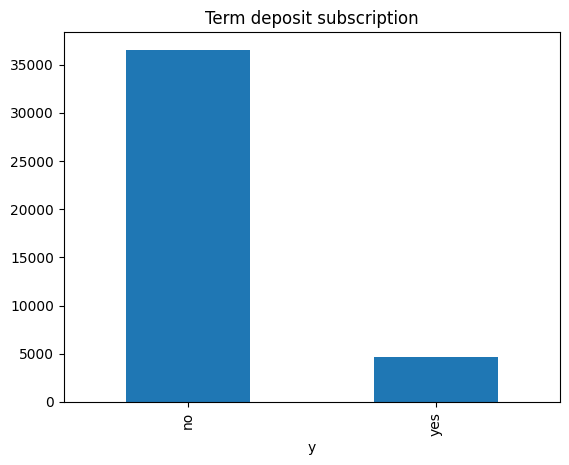

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [9]:
print(df['y'].value_counts()) #the target distribution
print(df['y'].value_counts(normalize=True).round(4))
df['y'].value_counts().plot(kind='bar', title='Term deposit subscription'); plt.show()

df.describe().T

### Data Understanding

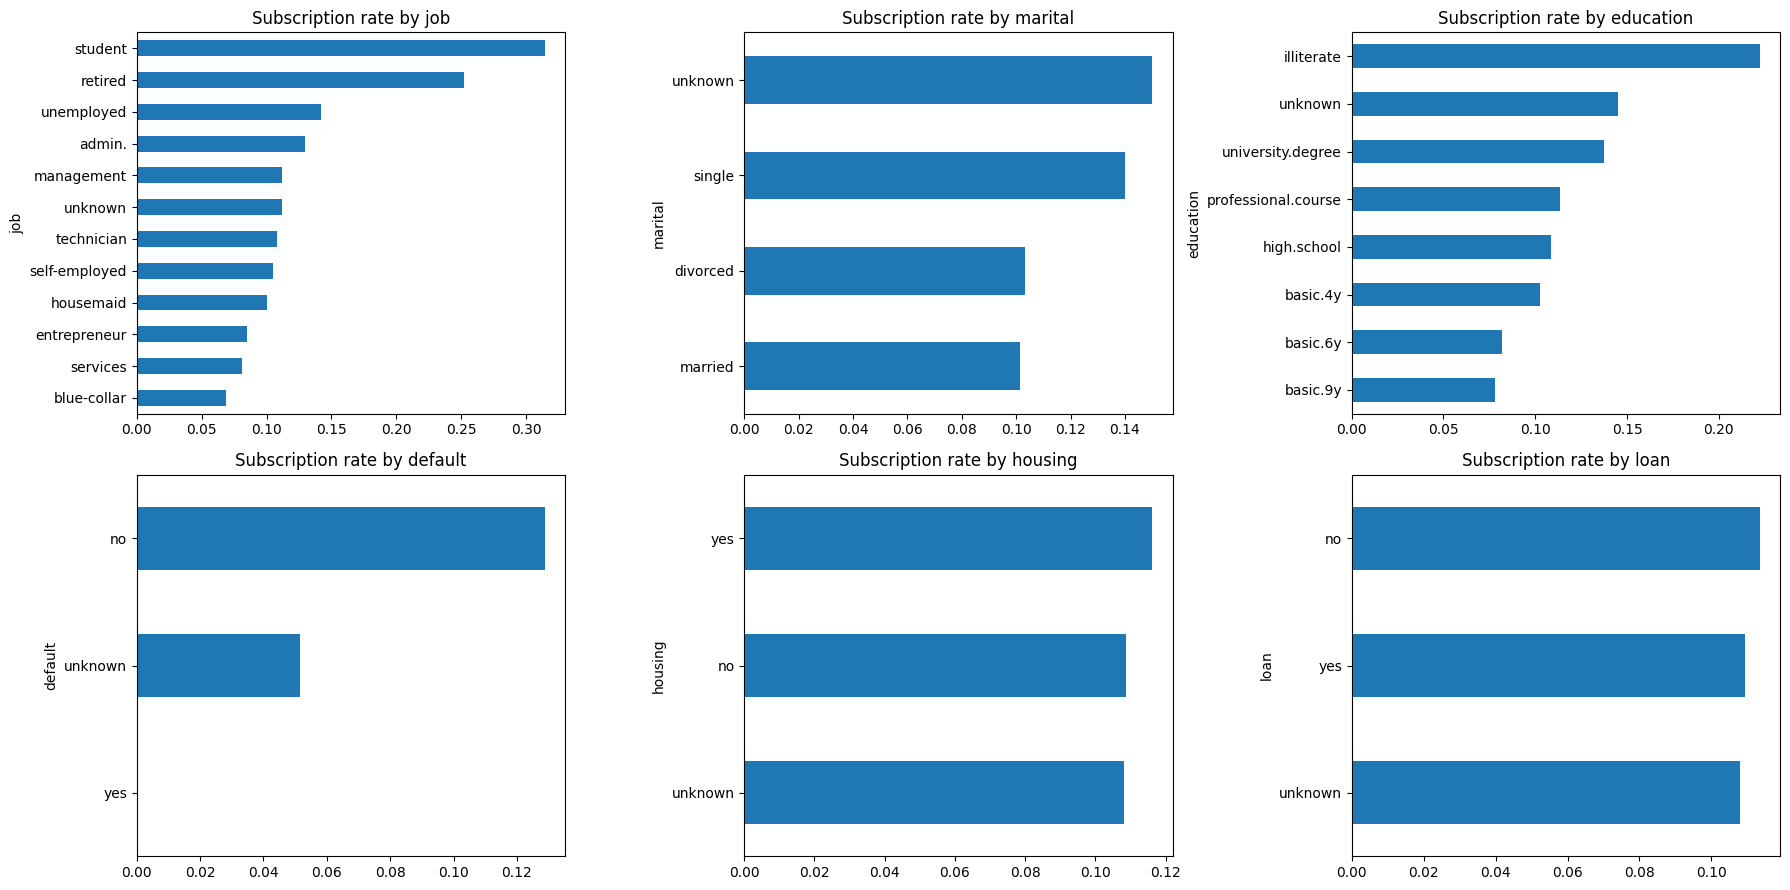

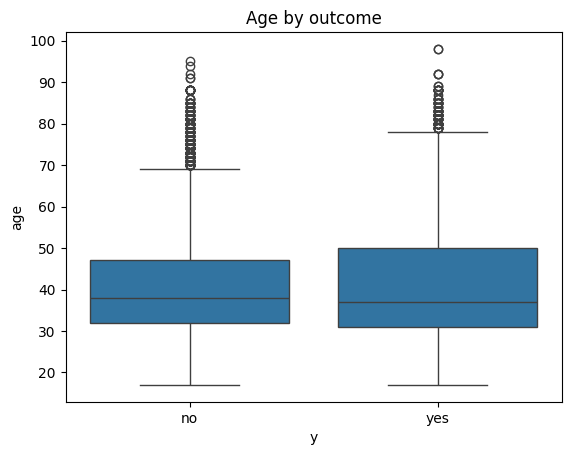

In [10]:
bank_cat = ['job','marital','education','default','housing','loan']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), bank_cat):
    rate = (df['y'].eq('yes')).groupby(df[col]).mean().sort_values()
    rate.plot(kind='barh', ax=ax, title=f'Subscription rate by {col}')
plt.tight_layout(); plt.show()

#graphs for subcription rates: job, marital, education, default, housing, loan

#box plot for age by outcome
sns.boxplot(data=df, x='y', y='age'); plt.title('Age by outcome'); plt.show()

In [25]:
#inferential stats

#CI for overall subscription rate
k, n = (df['y']=='yes').sum(), len(df)
lo, hi = proportion_confint(k, n, method='wilson')
print(f"Subscription rate = {k/n:.4f}, 95% CI [{lo:.4f}, {hi:.4f}]")

#test if each categorical feature is associated with y?
#chi sqaure tests
rows = []
for col in bank_cat:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df['y']))
    n_ = len(df); cramers_v = np.sqrt(chi2 / (n_ * (min(pd.crosstab(df[col], df['y']).shape) - 1)))
    rows.append([col, chi2, p, cramers_v])
chi_df = pd.DataFrame(rows, columns=['feature','chi2','p_value','cramers_V']).sort_values('p_value')

#Age vs y: Mann-Whitney and non-parametric
u, p = stats.mannwhitneyu(df.loc[df.y=='yes','age'], df.loc[df.y=='no','age'])
print(f"Age Mann-Whitney U p-value = {p:.4g}")

Subscription rate = 0.1127, 95% CI [0.1096, 0.1157]
Age Mann-Whitney U p-value = 0.01608


In [26]:
chi_df.round(4)

,feature,chi2,p_value,cramers_V
0,job,961.2424,0.0000,0.1528
3,default,406.5775,0.0000,0.0994
2,education,193.1059,0.0000,0.0685
1,marital,122.6552,0.0000,0.0546
4,housing,5.6845,0.0583,0.0117
5,loan,1.0940,0.5787,0.0052


- 95% Ci for the overall subcription rate, [0.1096, 0.1157]. So its very narrow because the n is large

In [13]:
#logistic regression with p-values and odds ratios
X_sm = pd.get_dummies(df[['age'] + bank_cat], drop_first=True).astype(float)
X_sm = sm.add_constant(X_sm)

logit = sm.Logit((df['y']=='yes').astype(int), X_sm).fit(disp=0)
res = pd.DataFrame({'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues})
res[res.p_value < 0.05].sort_values('odds_ratio', ascending=False)

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,odds_ratio,p_value
job_student,3.256243,2.723529e-43
job_retired,2.042318,2.929632e-19
marital_single,1.526332,3.939630e-12
job_unemployed,1.299066,6.846087e-03
education_unknown,1.257990,1.371459e-02
education_university.degree,1.193374,1.358854e-02
marital_married,1.152442,8.307254e-03
age,1.014422,1.006610e-13
loan_yes,0.945145,0.000000e+00
education_basic.9y,0.856560,3.954631e-02


### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [14]:
features = ['age'] + bank_cat
X = df[features]
y = (df['y'] == 'yes').astype(int)


preprocessor = ColumnTransformer([('num', StandardScaler(), ['age']), ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), bank_cat)])

- The 7 bank client features
- One-hot encoded the categoricals, with unknown as its own category,
- scaled age which is important for KNN and SVM
- mapped y to 1/0
- (duration is excluded because of it's leakage)

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

(28831, 7) (12357, 7) 0.1127 0.1126


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [16]:
base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print("Baseline accuracy:", round(base.score(X_test, y_test), 4))

Baseline accuracy: 0.8874


- the baseline accuracy shows 88.7%, so any model must beat this because it never identifies a single subscriber.
- its recall for yes is 0

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [17]:
lr = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000))])
lr.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan'])])),
                ('clf', LogisticRegression(max_iter=1000))])

### Problem 9: Score the Model

What is the accuracy of your model?

In [19]:
print("Train accuracy:", round(lr.score(X_train, y_train), 4))
print("Test accuracy:", round(lr.score(X_test, y_test), 4))
print(classification_report(y_test, lr.predict(X_test)))

Train accuracy: 0.8873
Test accuracy: 0.8874
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     10965
           1       0.00      0.00      0.00      1392

    accuracy                           0.89     12357
   macro avg       0.44      0.50      0.47     12357
weighted avg       0.79      0.89      0.83     12357



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [20]:
#the four models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC()
}

rows = []
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); t = time.perf_counter() - t0
    rows.append([name, round(t, 3), round(pipe.score(X_train, y_train), 4),
                 round(pipe.score(X_test, y_test), 4)])
results = pd.DataFrame(rows, columns=['Model','Train Time (s)','Train Accuracy','Test Accuracy'])
results

,Model,Train Time (s),Train Accuracy,Test Accuracy
0,Logistic Regression,0.324,0.8873,0.8874
1,KNN,0.237,0.8888,0.8749
2,Decision Tree,0.511,0.9188,0.8639
3,SVM,71.135,0.8883,0.8870


- All four models land near the 88.7% baseline.
- The Decision Tree has the highest train accuracy but a bigger train/test gap, from overfitting.
- SVM is the slowest to train.
- KNN is fast to fit but slow to predict.
- However, accuracy alone barely separates the models, so I need better metrics by improving the model

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [21]:
def get_scores(pipe, X_):
    clf = pipe.named_steps['clf']
    return pipe.predict_proba(X_)[:,1] if hasattr(clf,'predict_proba') else pipe.decision_function(X_)

def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    return [name, accuracy_score(y_test,pred), precision_score(y_test,pred,zero_division=0),
            recall_score(y_test,pred), f1_score(y_test,pred),
            roc_auc_score(y_test, get_scores(pipe, X_test))]



cols = ['Model','Accuracy','Precision','Recall','F1','ROC AUC']
default_rows = []
for name, clf in models.items():
    p = Pipeline([('prep', preprocessor), ('clf', clf)]).fit(X_train, y_train)
    default_rows.append(evaluate(name, p))

pd.DataFrame(default_rows, columns=cols).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.887,0.000,0.000,0.000,0.654
1,KNN,0.875,0.292,0.078,0.123,0.591
2,Decision Tree,0.864,0.227,0.087,0.126,0.568
3,SVM,0.887,0.452,0.014,0.026,0.576


In [22]:
# now onto hyperparameter tuning, scored on F1 and class-balanced

grids = {
    'Logistic Regression': (LogisticRegression(max_iter=1000),
        {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
        {'clf__n_neighbors': [5, 15, 31, 51], 'clf__weights': ['uniform','distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
        {'clf__max_depth': [3, 5, 8, 12], 'clf__min_samples_leaf': [10, 50, 100],
         'clf__class_weight': [None, 'balanced']}),
}

best, tuned_rows = {}, []

for name, (clf, grid) in grids.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    gs = GridSearchCV(pipe, grid, scoring='f1', cv=3, n_jobs=-1).fit(X_train, y_train)
    best[name] = gs.best_estimator_
    print(name, gs.best_params_, round(gs.best_score_, 3))
    tuned_rows.append(evaluate(name + ' (tuned)', gs.best_estimator_))

# Since SVM is slow, tune on a 10k subsample small grid
sub = X_train.sample(10000, random_state=42).index
svm_pipe = Pipeline([('prep', preprocessor), ('clf', SVC())])
gs = GridSearchCV(svm_pipe, {'clf__C': [0.1, 1], 'clf__kernel': ['rbf','linear'],'clf__class_weight': ['balanced']}, scoring='f1', cv=3, n_jobs=-1).fit(X_train.loc[sub], y_train.loc[sub])


print('SVM', gs.best_params_, round(gs.best_score_, 3))
best['SVM'] = gs.best_estimator_
tuned_rows.append(evaluate('SVM (tuned)', gs.best_estimator_))

final = pd.DataFrame(tuned_rows, columns=cols).round(3)
final

Logistic Regression {'clf__C': 1, 'clf__class_weight': 'balanced'} 0.257
KNN {'clf__n_neighbors': 5, 'clf__weights': 'distance'} 0.133
Decision Tree {'clf__class_weight': 'balanced', 'clf__max_depth': 12, 'clf__min_samples_leaf': 100} 0.261
SVM {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__kernel': 'rbf'} 0.262


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression (tuned),0.593,0.161,0.623,0.256,0.655
1,KNN (tuned),0.865,0.261,0.107,0.152,0.575
2,Decision Tree (tuned),0.609,0.157,0.568,0.247,0.647
3,SVM (tuned),0.625,0.166,0.578,0.258,0.637


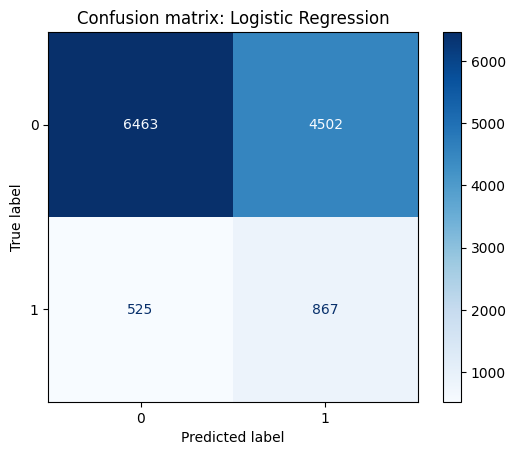

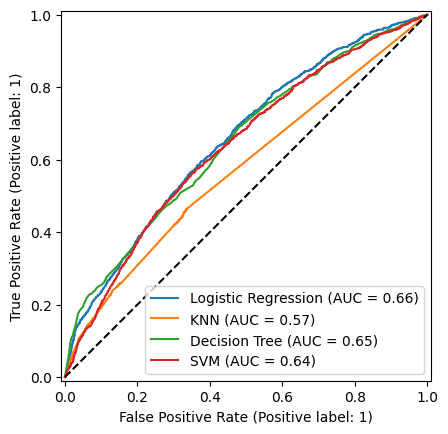

In [23]:
#confusion matrix and ROC for the best model

best_name = final.sort_values('ROC AUC', ascending = False).iloc[0,0].replace(' (tuned)','')
ConfusionMatrixDisplay.from_estimator(best[best_name], X_test, y_test, cmap='Blues')
plt.title(f'Confusion matrix: {best_name}'); plt.show()

from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots()
for n, m in best.items():
    RocCurveDisplay.from_predictions(y_test, get_scores(m, X_test), name=n, ax=ax)
ax.plot([0,1],[0,1],'k--'); plt.show()

#Summary
- Overall, the bank wanted to make telemarketing for term deposits more efficient by predicting, before dialing, which clients are likely to subscribe. A good model for this would reduce the number of calls and cost while preserving the number of successes.
- With 41,188 contacts, 20 predictors. Only 11.27% of contacts subscribed. Subscriptions rates vary by job, with students and retirees highest with a mean age of about 40 years

###Findings:
- Accuracy is misleading here: The baselinescores 88.7%. Default Logistic Regression and SVM match it (88.7%) while having almost no subscribers (recall 0.00 and 0.014). KNN (87.5%) and Decision Tree (86.4%) score even lower than the baseline.
- Default models barely beat chance at ranking: ROC AUC was 0.654 (Logistic Regression), 0.591 (KNN), 0.576 (SVM), and 0.568 (Decision Tree). Default recall was below 9% for every model.
- Tuning with class balancing helped a lot: Tuned Logistic Regression recall rose from 0.00 to 0.62 which tuned Decision Tree to 0.57, and tuned SVM to 0.58. KNN barely improved (F1 0.15) because it has no class-weight option.
- Cost of the trade-off: Accuracy fell from about 89% to about 60% and precision is only about 16%. The model catches more subscribers but flags many non-subscribers.
- The tuned models are essentially tied: F1 was 0.256 (Logistic Regression), 0.247 (Decision Tree), and 0.258 (SVM). AUC was 0.655, 0.647, and 0.637. These differences are too small to matter in practice.
- Best Model: Tuned Logistic Regression. It has the highest AUC (0.655), is the simplest and most interpretable, and trains in 0.3 seconds. The SVM took 71 seconds with default settings and only matched it.
- Practical Lift: Precision of 16.1% versus the 11.3% base rate means that the model's flagged clients are about 1.4 times more likely to subscribe than a random client. At recall 0.62, calling the flagged group would reach roughly 62% of subscribers while contacting only about 44% of clients.
- Bank-client features alone have limited predictive power: Even the best AUC (about 0.65) is modest. Subscription likely depends more on timing, economic conditions, and prior-campaign history than on who the client is.

###Inferential statistics
- The overall subscription rate is 11.27% (95% CI [10.96%, 11.57%]). Age differs greatly by outcome (Mann-Whitney p = 0.016), but the medians are almost identical (about 37-38), so the effect is practically small.
- In the logistic regression, students (odds ratio 3.26) and retirees (2.04) have the highest odds of subscribing, followed by single clients (1.53).
- Blue-collar workers (0.68), entrepreneurs (0.69), and services (0.74) have lower odds.
- Clients with 'unknown' default status have much lower odds (0.39). With over 41,000 rows, small effects reach significance, so effect sizes matter more than p-values.


### Actionable Insighs
- Prioritize high-yield segments: Students (31% subscription rate) and retirees (25%) subscribe at 2-3 times the overall average. Singles and university-educated clients also respond better.
- Deprioritize low-yield segments: Blue-collar workers (7%), services (8%), and entrepreneurs (8.5%) subscribe the least compared to other groups.
- Use model scores to rank the call list: Call the highest-scoring clients first instead of dialing everyone.
- Treat 'unknown' default status as a data-quality signal.** These clients subscribe at about 5% versus 13% for "no". Improving data collection could sharpen targeting, and these contacts are lower priority.
- Choose the threshold by business cost: A lower threshold reaches more subscribers but wastes more calls. The bank should pick it by comparing cost per call to the value of a deposit.

### Next Steps and Recommendations

1. Use recall, F1, AUC, and lift instead of accuracy as the evaluation standard for this problem.
2. Add the non-leaky campaign and economic features: contact type, month, day of week, previous outcome, euribor3m, employment and confidence indicators. Then find thetiming and economic context to improve predictions. This is the most promising way to raise AUC above 0.65.
3. Continue Keeping 'duration' excluded.
4. Try stronger models, like a Random Forest or Gradient Boosting, with cross-validation and a full SVM grid search on more data.
5. Collect richer client data, like balance, income, product holdings, which the paper's authors also recommend.
6. Monitor and retrain, since the data covers 2008-2010 which was during a financial crisis, so patterns may not hold for current clients.

##### Questions